In [6]:
# 2. import pandas as pd
import pandas as pd
import math
from collections import Counter
from nltk.util import bigrams, trigrams, ngrams

In [43]:
# 3. Loading Dataset
df = pd.read_pickle("../pertemuan-03/processed_text_backup.pkl")

df.to_csv(
    "../pertemuan-03/processed_text_backup.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Jumlah baris:", len(df))

Jumlah baris: 225002


In [44]:
# 4. Membuat Corpus Token
df = pd.read_csv(
    "../pertemuan-03/dataset_preprocessed_final.csv",
    low_memory=False
)

text_column = "processed_text"

# Menghapus nilai kosong
df = df.dropna(subset=[text_column])
df = df[df[text_column].astype(str).str.strip().ne("")]

all_text = " ".join(df[text_column].astype(str))
tokens = all_text.split()

print("Jumlah dokumen:", len(df))
print("Total token:", len(tokens))
print("Contoh token:", tokens[:20])
print("Pada tahap ini, 221.099 dokumen digabungkan dan dipisahkan menjadi kata-kata. Hasilnya terdapat 1.264.184 token yang digunakan untuk analisis selanjutnya.")

Jumlah dokumen: 221099
Total token: 1264184
Contoh token: ['akun', 'gopay', 'blok', 'lambat', 'bosssku', 'apk', 'gojek', 'gk', 'kaya', 'sih', 'kemarin', 'sy', 'buka', 'aplikasi', 'gojek', 'kasih', 'bintang', 'kalo', 'normal', 'sy']
Pada tahap ini, 221.099 dokumen digabungkan dan dipisahkan menjadi kata-kata. Hasilnya terdapat 1.264.184 token yang digunakan untuk analisis selanjutnya.


In [47]:
# 5. Membuat Unigram
unigram = Counter(tokens)

print("20 Kata Paling Sering Muncul:")
for word, count in unigram.most_common(20):
    print(f"  {word:<20} : {count}")

20 Kata Paling Sering Muncul:
  gojek                : 33122
  aplikasi             : 24895
  nya                  : 22082
  bantu                : 22017
  driver               : 18746
  bagus                : 17813
  yg                   : 16182
  mantap               : 15394
  ok                   : 13819
  ga                   : 13596
  gak                  : 12711
  gopay                : 12088
  good                 : 10758
  banget               : 9172
  aja                  : 9014
  promo                : 7984
  layan                : 7837
  ya                   : 7787
  mudah                : 7748
  tolong               : 7734


In [48]:
# 6. Probabilitas Unigram
total_tokens = sum(unigram.values())

unigram_probability = {
    word: count / total_tokens
    for word, count in unigram.items()
}

print("\n10 Kata dengan Probabilitas Tertinggi:")
sorted_prob = sorted(
    unigram_probability.items(),
    key=lambda x: x[1],
    reverse=True
)
for word, prob in sorted_prob[:10]:
    print(f"  {word:<20} : {prob:.6f}")


10 Kata dengan Probabilitas Tertinggi:
  gojek                : 0.026200
  aplikasi             : 0.019693
  nya                  : 0.017467
  bantu                : 0.017416
  driver               : 0.014829
  bagus                : 0.014091
  yg                   : 0.012800
  mantap               : 0.012177
  ok                   : 0.010931
  ga                   : 0.010755


In [49]:
# 7. Membuat Bigram
bigram_tokens = list(bigrams(tokens))
bigram_frequency = Counter(bigram_tokens)

print("20 Bigram Paling Sering Muncul:")
for bigram, count in bigram_frequency.most_common(20):
    print(f"  {' '.join(bigram):<30} : {count}")

20 Bigram Paling Sering Muncul:
  aplikasi gojek                 : 2680
  terima kasih                   : 2244
  driver nya                     : 2100
  top up                         : 1725
  aplikasi nya                   : 1539
  tolong baik                    : 1340
  driver yg                      : 1314
  gojek bantu                    : 1307
  saldo gopay                    : 1231
  go food                        : 1193
  aplikasi bantu                 : 1191
  kasih bintang                  : 1171
  bagus bantu                    : 1162
  pakai gojek                    : 1136
  the best                       : 1114
  pake gojek                     : 1103
  aplikasi bagus                 : 1078
  aplikasi yg                    : 1013
  good job                       : 1002
  cari driver                    : 961


In [50]:
# 8. Membuat Trigram
trigram_tokens = list(trigrams(tokens))
trigram_frequency = Counter(trigram_tokens)

print("20 Trigram Paling Sering Muncul:")
for trigram, count in trigram_frequency.most_common(20):
    print(f"  {' '.join(trigram):<40} : {count}")

20 Trigram Paling Sering Muncul:
  terima kasih gojek                       : 515
  upgrade gopay plus                       : 466
  top up gopay                             : 354
  karya anak bangsa                        : 344
  is the best                              : 314
  aplikasi yg bantu                        : 285
  biaya jasa aplikasi                      : 250
  aplikasi nya bagus                       : 240
  susah cari driver                        : 205
  bantu terima kasih                       : 202
  driver nya ramah                         : 202
  top up saldo                             : 186
  pakai aplikasi gojek                     : 185
  aplikasi gojek bantu                     : 184
  gojek is the                             : 163
  so far so                                : 143
  far so good                              : 133
  terima kasih bantu                       : 128
  isi saldo gopay                          : 124
  pesan go food                     

In [ ]:
# 9. Conditional Probability Bigram
def bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)]
    denominator = unigram[word1]

    if denominator == 0:
        return 0.0

    return numerator / denominator

# Contoh pasangan kata dari dataset
word1, word2 = "aplikasi", "gojek"
prob = bigram_probability(word1, word2)

print(f"P({word2} | {word1}) = {prob:.6f}")

# Artinya, probabilitas kata gojek muncul setelah kata aplikasi adalah sekitar 10,77% berdasarkan dataset ulasan Gojek.

P(gojek | aplikasi) = 0.107652


In [63]:
# 10. Probabilitas Kalimat 
# Menggunakan bigram untuk menghitung probabilitas kalimat:
def sentence_probability(sentence):
    words = sentence.lower().split()
    probability = 1.0

    for i in range(len(words) - 1):
        p = bigram_probability(words[i], words[i + 1])
        probability *= p

    return probability

# Uji probabilitas kalimat
test_sentences = [
    "aplikasi gojek",
    "gojek bagus",
    "gopay gagal transaksi"
]

for sentence in test_sentences:
    p = sentence_probability(sentence)
    print(f"P('{sentence}') = {p:.8f}")

P('aplikasi gojek') = 0.10765214
P('gojek bagus') = 0.01850734
P('gopay gagal transaksi') = 0.00007307


In [66]:
# 11. Laplace Smoothing
vocab_size = len(unigram)

def smoothed_bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)] + 1
    denominator = unigram[word1] + vocab_size
    return numerator / denominator

# Uji dengan kata yang mungkin tidak ada dalam corpus
word1, word2 = "aplikasi", "lemot"
prob = smoothed_bigram_probability(word1, word2)
print(f"Smoothed P({word2} | {word1}) = {prob:.8f}")

Smoothed P(lemot | aplikasi) = 0.00001126


In [70]:
# 12. Prediksi Kata Sederhana
def predict_next_word(context_word, top_n=5):
    candidates = []

    for (word1, word2), count in bigram_frequency.items():
        if word1 == context_word:
            p = smoothed_bigram_probability(word1, word2)
            candidates.append((word2, p))

    candidates.sort(key=lambda x: x[1], reverse=True)
    return candidates[:top_n]

# Contoh
context = "aplikasi"
predictions = predict_next_word(context)
print(f"\nPrediksi kata setelah '{context}':")
for word, prob in predictions:
    print(f"  {word:<20} : {prob:.6f}")


Prediksi kata setelah 'aplikasi':
  gojek                : 0.030186
  nya                  : 0.017339
  bantu                : 0.013421
  bagus                : 0.012149
  yg                   : 0.011417


In [72]:
# 13. Menghitung Perplexity
def perplexity(probability, N):
    if probability == 0 or probability is None:
        return float("inf")
    return probability ** (-1 / N)

# Contoh
sentence = "aplikasi gojek"
words = sentence.split()
prob = sentence_probability(sentence)
N = len(words)

pp = perplexity(prob, N)
print(f"Kalimat : '{sentence}'")
print(f"P(W)    : {prob:.8f}")
print(f"N       : {N}")
print(f"PP(W)   : {pp:.4f}")

Kalimat : 'aplikasi gojek'
P(W)    : 0.10765214
N       : 2
PP(W)   : 3.0478


In [73]:
# 14. Perbandingan Ungram, Bigram, dan Trigram
print("=" * 60)
print("PERBANDINGAN MODEL N-GRAM")
print("=" * 60)
print(f"Ukuran Vocabulary     : {len(unigram):,}")
print(f"Jumlah Token          : {len(tokens):,}")
print(f"Jumlah Unigram unik   : {len(unigram):,}")
print(f"Jumlah Bigram unik    : {len(bigram_frequency):,}")
print(f"Jumlah Trigram unik   : {len(trigram_frequency):,}")
print()

# Cek sparsity
max_bigram = len(unigram) ** 2
max_trigram = len(unigram) ** 3
print(f"Kemungkinan Bigram maks  : {max_bigram:,}")
print(f"Bigram yang ada          : {len(bigram_frequency):,}")
print(f"Bigram coverage          : {len(bigram_frequency)/max_bigram*100:.4f}%")

PERBANDINGAN MODEL N-GRAM
Ukuran Vocabulary     : 63,920
Jumlah Token          : 1,264,184
Jumlah Unigram unik   : 63,920
Jumlah Bigram unik    : 516,938
Jumlah Trigram unik   : 1,076,638

Kemungkinan Bigram maks  : 4,085,766,400
Bigram yang ada          : 516,938
Bigram coverage          : 0.0127%


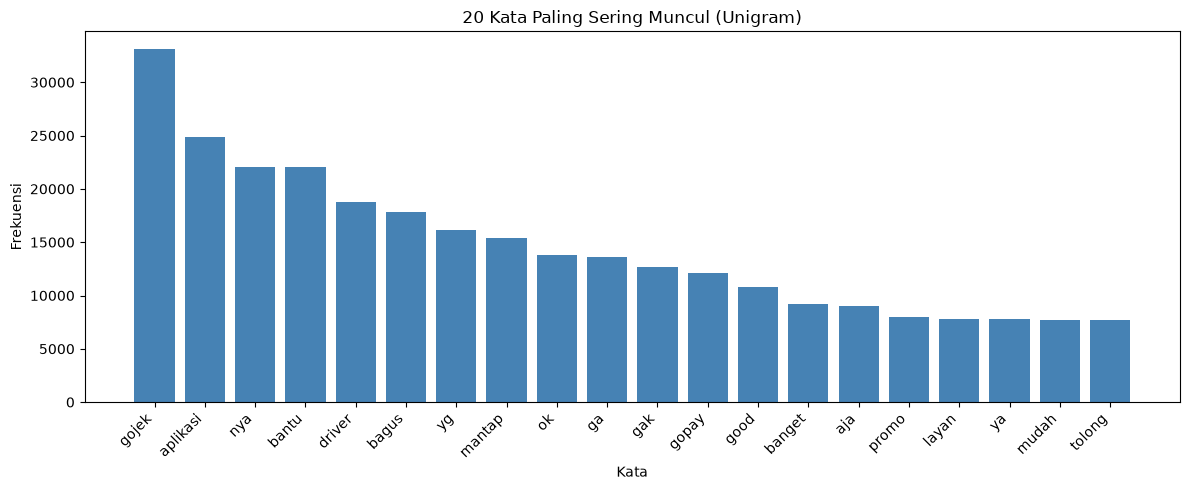

In [74]:
# 15. Visualisasi 
import matplotlib.pyplot as plt

# Top 20 unigram
top_words = unigram.most_common(20)
words_list = [w[0] for w in top_words]
counts_list = [w[1] for w in top_words]

plt.figure(figsize=(12, 5))
plt.bar(words_list, counts_list, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kata")
plt.ylabel("Frekuensi")
plt.title("20 Kata Paling Sering Muncul (Unigram)")
plt.tight_layout()
plt.show()